# 03 · Backtest framework and conventional models

**Design (identical for every model, including the AI models in notebooks 05–06)**
- Rolling origin, expanding window: at each origin (every Monday from 30 Jun 2025 to 28 Sep 2026, 66 origins) fit on all data up to and including that Monday, forecast 1–12 weeks ahead.
- Scored horizons: 4 and 12 weeks. Targets after the last observed week are not scored, so h = 12 has fewer scored forecasts than h = 4.
- Log prices for fitting; forecasts and 80% intervals converted back to USD/gal before scoring.
- No future information: ARIMAX uses only crude prices known at the origin; future crude follows a random walk (no change). Event dummies are held at their state on the origin date.

Framework code: `src/common.py` (backtest loop, forecast file format, metrics, Diebold–Mariano). Model code: `src/models_conventional.py`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
import plots; plots.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
df = load_weekly()
from models_conventional import MODELS
ol = origins(df)
print(len(ol), "origins:", ol[0].date(), "→", ol[-1].date())

66 origins: 2025-06-30 → 2026-09-28


## Models
| model | what it does |
|---|---|
| `naive` | last observed price (random walk); intervals from historical h-week log changes |
| `seasonal_naive` | price 52 weeks before the target week |
| `ets` | exponential smoothing on log price; error/trend type and damping chosen by AICc |
| `arima_fourier` | auto-selected ARIMA on log price with 3 Fourier pairs for the 52.18-week season |
| `arimax` | `arima_fourier` + Brent weekly log changes (lags 0–3, where lag 0 = previous week's average) + COVID dummy + count of permanent CA refinery closures |
| `arimax_lags1to4` | robustness check: same as `arimax` but crude lags 1–4, dropping the most recent crude week known at the origin |

In [2]:
import time
fcs = {}
for name, f in MODELS.items():
    t = time.time()
    fcs[name] = rolling_backtest(df, name, f, ol, verbose=False)
    print(f"{name:16s} done in {time.time() - t:6.1f}s")

naive            done in    0.2s


seasonal_naive   done in    0.1s


ets              done in    5.1s


arima_fourier    done in  146.2s


arimax           done in  212.6s


arimax_lags1to4  done in  179.1s


## Quick accuracy check (full comparison with AI models is in notebook 07)

In [3]:
fc = attach_actuals(pd.concat(fcs.values()), df)
tab = fc[fc.horizon.isin(SCORED_H)].groupby(["horizon", "model"]).apply(metrics).round(3)
naive_mae = tab.xs("naive", level="model")["MAE"]
tab["skill_vs_naive"] = (tab["MAE"] / tab.index.get_level_values("horizon").map(naive_mae)).round(3)
tab

n    MAE   RMSE    MAPE   bias  cover80  skill_vs_naive
horizon model                                                                      
4       arima_fourier    63.0  0.217  0.311   4.104  0.105    0.810           0.804
        arimax           63.0  0.213  0.305   4.030  0.116    0.889           0.789
        arimax_lags1to4  63.0  0.218  0.309   4.125  0.105    0.825           0.807
        ets              63.0  0.268  0.364   5.199  0.076    0.651           0.993
        naive            63.0  0.270  0.384   5.233  0.111    0.794           1.000
        seasonal_naive   63.0  0.631  0.848  11.421  0.574    0.968           2.337
12      arima_fourier    55.0  0.412  0.581   7.551  0.340    0.745           0.687
        arimax           55.0  0.397  0.573   7.265  0.351    0.745           0.662
        arimax_lags1to4  55.0  0.410  0.577   7.509  0.332    0.745           0.683
        ets              55.0  0.694  0.879  12.944  0.232    0.655           1.157
        naive            55.0  0.600  0.812  11.109  0.294    0.782           1.000
        seasonal_naive   55.0  0.715  0.907  12.895  0.665    0.964           1.192

## What did the models see at a few origins?

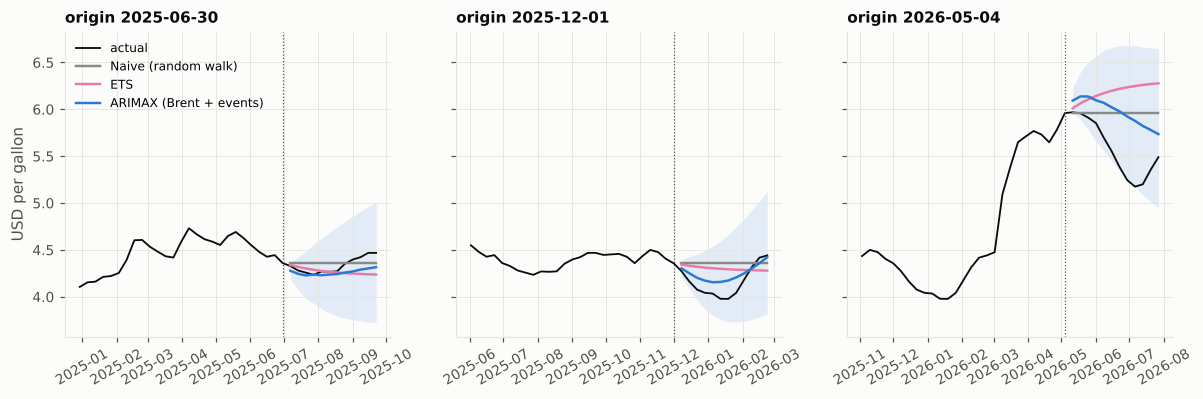

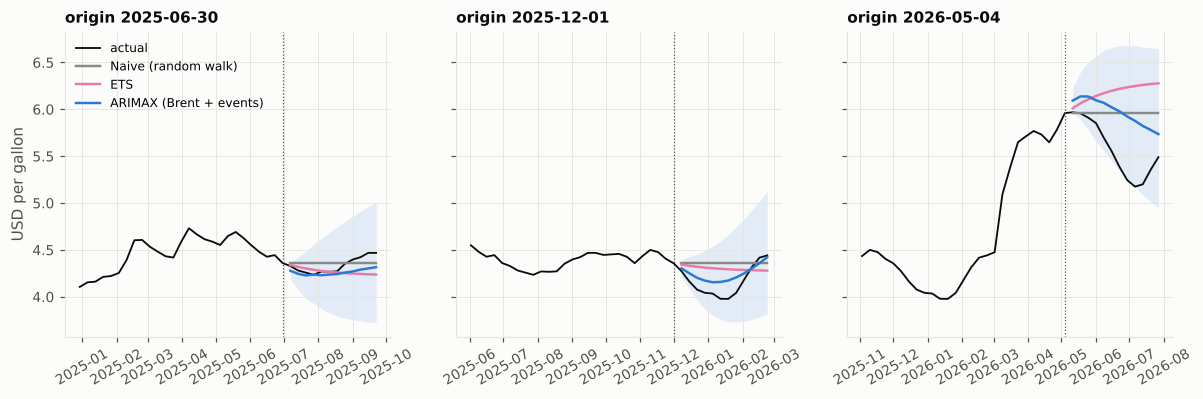

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, o in zip(axes, [ol[0], ol[len(ol) // 3], ol[2 * len(ol) // 3]]):
    hist = df.ca_gas.loc[o - pd.Timedelta(weeks=26):o + pd.Timedelta(weeks=12)]
    ax.plot(hist.index, hist.values, color=plots.INK, lw=1.2, label="actual")
    for m in ["naive", "ets", "arimax"]:
        g = fcs[m][fcs[m].origin_date == o]
        ax.plot(g.target_date, g.forecast, color=plots.MODEL_COLORS[m], label=plots.MODEL_LABELS[m])
    g = fcs["arimax"][fcs["arimax"].origin_date == o]
    ax.fill_between(g.target_date, g.lower80, g.upper80, color=plots.MODEL_COLORS["arimax"], alpha=0.12, lw=0)
    ax.axvline(o, color=plots.INK2, ls=":", lw=0.8); ax.set_title(f"origin {o.date()}", fontsize=10)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("USD per gallon"); axes[0].legend(fontsize=8, loc="upper left")
fig